In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Student Marks Analyzer Started!")

Student Marks Analyzer Started!


In [2]:
data = {
    "Student_ID": [101, 102, 103, 104, 105,
                   106, 107, 108, 109, 110],

    "Name": ["Aarav", "Riya", "Kabir", "Ananya", "Arjun",
             "Meera", "Ishaan", "Sara", "Vivaan", "Diya"],

    "Maths": [85, 92, 67, 78, 55, 95, 72, 88, 60, 81],

    "Science": [90, 89, 70, 82, 60, 94, 75, 91, 65, 84],

    "English": [78, 95, 80, 85, 58, 90, 68, 92, 70, 88]
}

df = pd.DataFrame(data)

df

,Student_ID,Name,Maths,Science,English
0,101,Aarav,85,90,78
1,102,Riya,92,89,95
2,103,Kabir,67,70,80
3,104,Ananya,78,82,85
4,105,Arjun,55,60,58
5,106,Meera,95,94,90
6,107,Ishaan,72,75,68
7,108,Sara,88,91,92
8,109,Vivaan,60,65,70
9,110,Diya,81,84,88


In [3]:
subjects = ["Maths", "Science", "English"]

df["Total"] = df[subjects].sum(axis=1)

df["Average"] = df[subjects].mean(axis=1)

df["Percentage"] = (df["Total"] / 300) * 100

df[["Student_ID", "Name", "Total", "Average", "Percentage"]]

,Student_ID,Name,Total,Average,Percentage
0,101,Aarav,253,84.333333,84.333333
1,102,Riya,276,92.000000,92.000000
2,103,Kabir,217,72.333333,72.333333
3,104,Ananya,245,81.666667,81.666667
4,105,Arjun,173,57.666667,57.666667
5,106,Meera,279,93.000000,93.000000
6,107,Ishaan,215,71.666667,71.666667
7,108,Sara,271,90.333333,90.333333
8,109,Vivaan,195,65.000000,65.000000
9,110,Diya,253,84.333333,84.333333


In [4]:
def calculate_grade(percentage):

    if percentage >= 90:
        return "A+"

    elif percentage >= 80:
        return "A"

    elif percentage >= 70:
        return "B"

    elif percentage >= 60:
        return "C"

    elif percentage >= 50:
        return "D"

    else:
        return "F"


df["Grade"] = df["Percentage"].apply(calculate_grade)

df[["Name", "Percentage", "Grade"]]

,Name,Percentage,Grade
0,Aarav,84.333333,A
1,Riya,92.000000,A+
2,Kabir,72.333333,B
3,Ananya,81.666667,A
4,Arjun,57.666667,D
5,Meera,93.000000,A+
6,Ishaan,71.666667,B
7,Sara,90.333333,A+
8,Vivaan,65.000000,C
9,Diya,84.333333,A


In [5]:
def check_result(row):

    if all(row[subject] >= 35 for subject in subjects):
        return "Pass"

    else:
        return "Fail"


df["Result"] = df.apply(check_result, axis=1)

df[["Name", "Maths", "Science", "English", "Result"]]

,Name,Maths,Science,English,Result
0,Aarav,85,90,78,Pass
1,Riya,92,89,95,Pass
2,Kabir,67,70,80,Pass
3,Ananya,78,82,85,Pass
4,Arjun,55,60,58,Pass
5,Meera,95,94,90,Pass
6,Ishaan,72,75,68,Pass
7,Sara,88,91,92,Pass
8,Vivaan,60,65,70,Pass
9,Diya,81,84,88,Pass


In [6]:
print("CLASS PERFORMANCE REPORT")
print("-------------------------")

print("Total Students:", len(df))

print("Class Average:",
      round(df["Percentage"].mean(), 2), "%")

print("Highest Percentage:",
      round(df["Percentage"].max(), 2), "%")

print("Lowest Percentage:",
      round(df["Percentage"].min(), 2), "%")

print("Students Passed:",
      (df["Result"] == "Pass").sum())

print("Students Failed:",
      (df["Result"] == "Fail").sum())

CLASS PERFORMANCE REPORT
-------------------------
Total Students: 10
Class Average: 79.23 %
Highest Percentage: 93.0 %
Lowest Percentage: 57.67 %
Students Passed: 10
Students Failed: 0


In [7]:
subject_averages = df[subjects].mean()

print("SUBJECT PERFORMANCE")
print("-------------------")

for subject, average in subject_averages.items():

    print(subject, "Average:", round(average, 2))

SUBJECT PERFORMANCE
-------------------
Maths Average: 77.3
Science Average: 80.0
English Average: 80.4


In [8]:
top_students = df.sort_values(
    by="Percentage",
    ascending=False
).head(5)

print("TOP 5 STUDENTS")

top_students[["Name", "Total", "Percentage", "Grade"]]

TOP 5 STUDENTS


,Name,Total,Percentage,Grade
5,Meera,279,93.000000,A+
1,Riya,276,92.000000,A+
7,Sara,271,90.333333,A+
0,Aarav,253,84.333333,A
9,Diya,253,84.333333,A


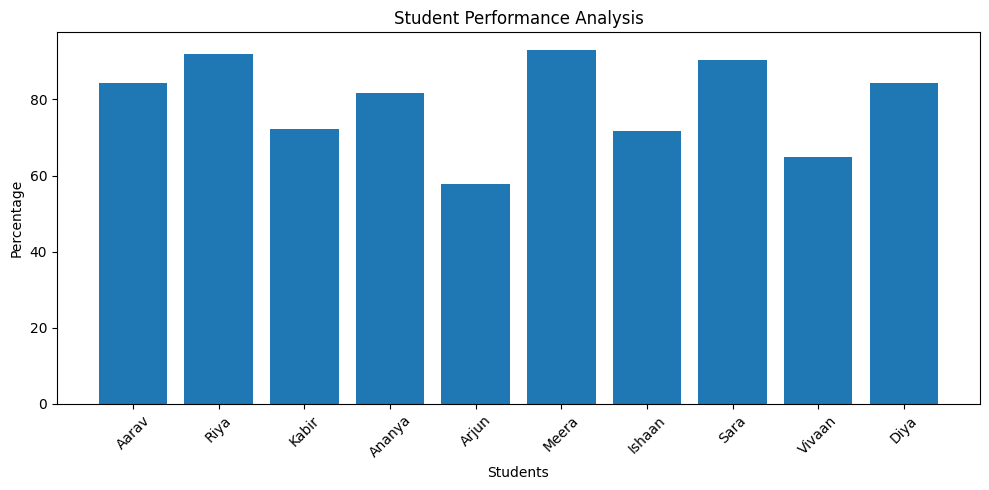

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(df["Name"], df["Percentage"])

plt.xlabel("Students")
plt.ylabel("Percentage")

plt.title("Student Performance Analysis")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

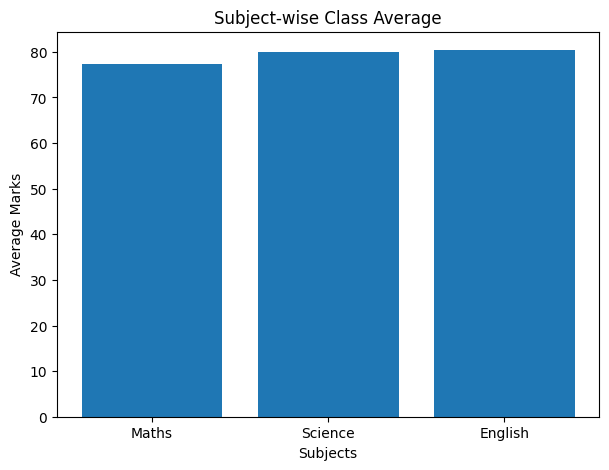

In [10]:
plt.figure(figsize=(7, 5))

plt.bar(
    subject_averages.index,
    subject_averages.values
)

plt.xlabel("Subjects")
plt.ylabel("Average Marks")

plt.title("Subject-wise Class Average")

plt.show()

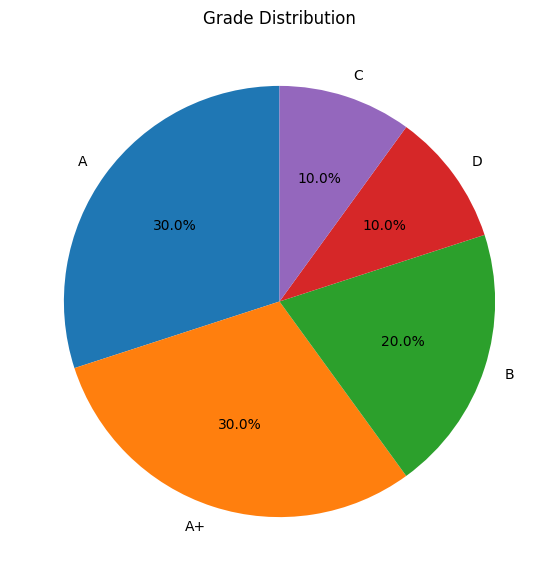

In [11]:
grade_counts = df["Grade"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    grade_counts.values,
    labels=grade_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Grade Distribution")

plt.show()

In [12]:
student_name = input("Enter student name: ")

result = df[
    df["Name"].str.lower() == student_name.lower()
]

if not result.empty:

    print("STUDENT RECORD FOUND")

    display(result)

else:

    print("Student not found!")

Enter student name: riya
STUDENT RECORD FOUND


,Student_ID,Name,Maths,Science,English,Total,Average,Percentage,Grade,Result
1,102,Riya,92,89,95,276,92.0,92.0,A+,Pass


In [13]:
df.to_csv("student_marks_report.csv", index=False)

print("Report exported successfully!")

Report exported successfully!
